In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.fft import rfft, rfftfreq, irfft

import scipy.signal

import scipy.optimize

plt.rcParams["figure.figsize"] = (10,8)


In [2]:
df_L05S03_L05S03 = pd.read_csv("data/high_stat_2/stim_L05S03_recv_L05S03.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S04_L05S04 = pd.read_csv("data/high_stat_2/stim_L05S04_recv_L05S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L05S05 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L05S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L05S04 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L05S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L15S05 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L15S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L05S03 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L05S03.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])

df_L45S05_L45S05 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L45S04 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L45S03 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S03.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L55S05 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L55S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])


dfs = { "L05S03_L05S03": df_L05S03_L05S03,
        "L05S04_L05S04": df_L05S04_L05S04,
        "L05S05_L05S05": df_L05S05_L05S05,
        "L05S05_L05S04": df_L05S05_L05S04,
        "L05S05_L15S05": df_L05S05_L15S05,
        "L45S05_L45S05": df_L45S05_L45S05,
        "L45S05_L45S04": df_L45S05_L45S04,
        "L45S05_L45S03": df_L45S05_L45S03,
        "L45S05_L55S05": df_L45S05_L55S05,
        "L05S05_L15S05": df_L05S05_L15S05,
        "L05S05_L05S03": df_L05S05_L05S03 }

keys_thru = ["L05S03_L05S03", "L05S04_L05S04", "L05S05_L05S05", "L45S05_L45S05"]
keys_xtalk = ["L05S05_L05S04", "L05S05_L05S03", "L05S05_L15S05", "L45S05_L45S04", "L45S05_L45S03", "L45S05_L55S05"]

for key in dfs:
    dft = dfs[key]
    dft['s11_p'] = dft['s11_p'] / 180.0 * np.pi
    dft['s11_p'] = np.unwrap(dft['s11_p'])

    dft['s21_p'] = dft['s21_p'] / 180.0 * np.pi
    dft['s21_p'] = np.unwrap(dft['s21_p'])

    dft['s11_c'] = dft['s11_m'] * np.exp(1j * dft['s11_p'])
    dft['s21_c'] = dft['s21_m'] * np.exp(1j * dft['s21_p'])





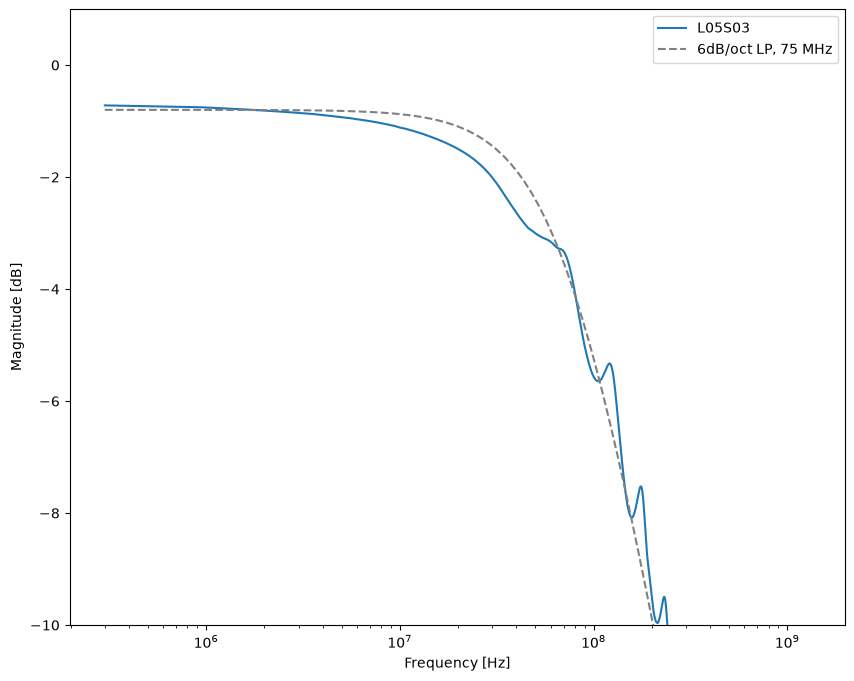

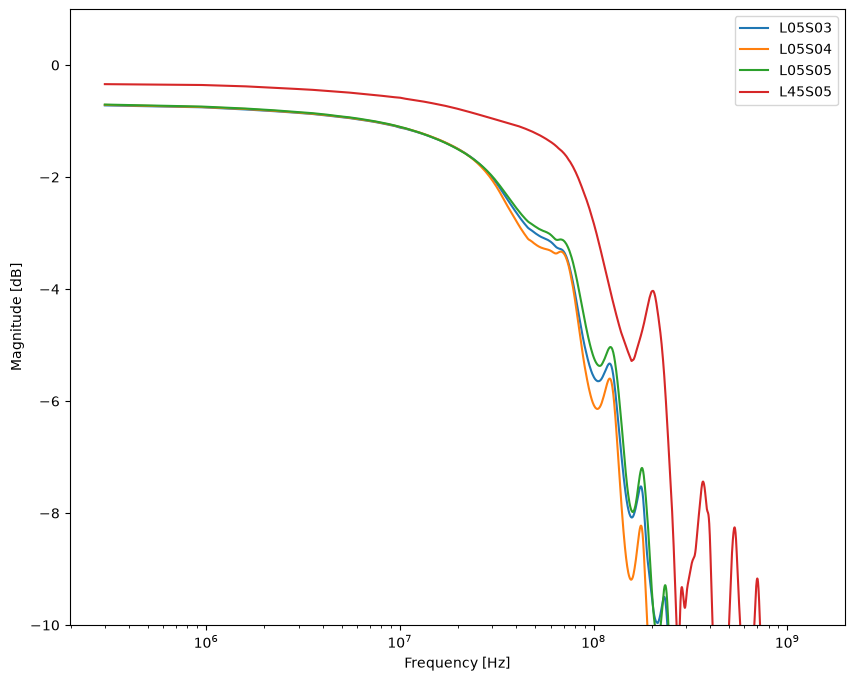

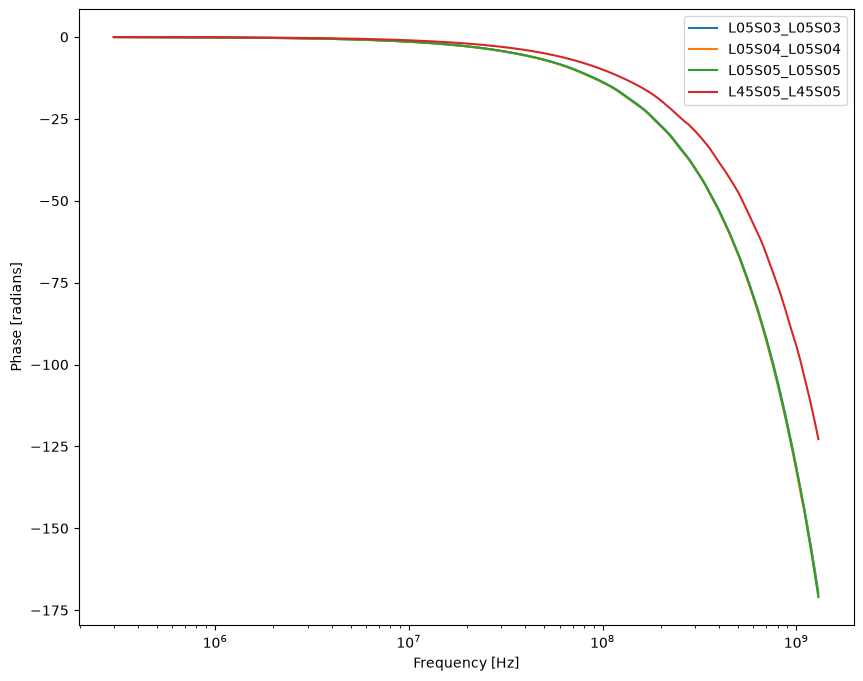

In [3]:
def lowpass_mag(freq, f_c, offset):
    return 20*np.log10(1/np.sqrt(1+(freq/np.power(10, f_c))**2)) + offset

def lowpass_mag_lin(freq, f_c, offset):
    return 20*np.log10(1/np.sqrt(1+(freq/f_c)**2)) + offset


xx = np.logspace(np.log10(dfs['L05S03_L05S03']['freq'].min()), np.log10(dfs['L05S03_L05S03']['freq'].max()), 100)

for key in ['L05S03_L05S03']:
    dft = dfs[key]
    plt.plot(dft['freq'], dft['s21_m'], label = f'{key[:6]}')

    # ax1.plot(dft['freq'], lowpass_mag(dft['freq'], 8, 0), label = key)

    # xx = np.logspace(np.log10(dft['freq'].min()), np.log10(dft['freq'].max()), 100)

    # #popt, pcov = scipy.optimize.curve_fit(lowpass_mag, xx, np.interp(xx, dft['freq'], dft['s21_m']), p0=[8, 0])

    # print(key, popt)

    plt.plot(xx, lowpass_mag_lin(xx, *[75E6,-.8]), '--', color = f'grey', label = f'6dB/oct LP, {75} MHz')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude [dB]')


    
plt.legend()
plt.xscale('log')
plt.ylim(-10, 1)

plt.savefig('s21_thru_magnitude_L05S03_L05S03.pdf')

plt.show()

for key in keys_thru:
    dft = dfs[key]
    plt.plot(dft['freq'], dft['s21_m'], label = f'{key[:6]}')

    # ax1.plot(dft['freq'], lowpass_mag(dft['freq'], 8, 0), label = key)

    # xx = np.logspace(np.log10(dft['freq'].min()), np.log10(dft['freq'].max()), 100)

    # popt, pcov = scipy.optimize.curve_fit(lowpass_mag, xx, np.interp(xx, dft['freq'], dft['s21_m']), p0=[8, 0])

    # print(key, popt)

    # ax1.plot(xx, lowpass_mag(xx, *popt), '.', label = f'lowpass fit ({key})')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude [dB]')


    
plt.legend()
plt.xscale('log')
plt.ylim(-10, 1)

plt.savefig('s21_thru_magnitude_all.pdf')

plt.show()

for key in keys_thru:
    dft = dfs[key]
    plt.plot(dft['freq'], dft['s21_p'], label = key)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Phase [radians]')

plt.legend()
plt.xscale('log')

plt.savefig('s21_thru_phase_all.pdf')

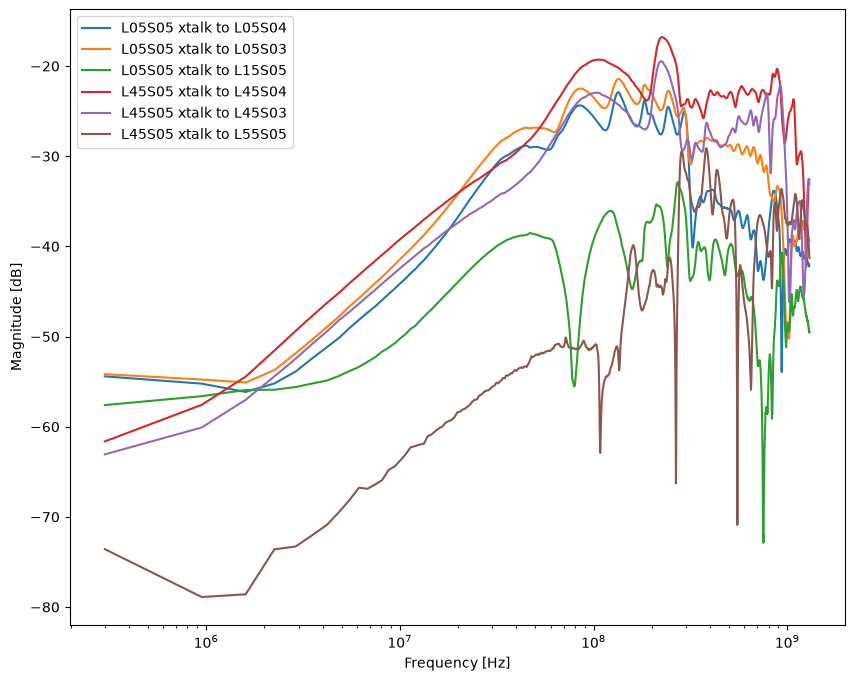

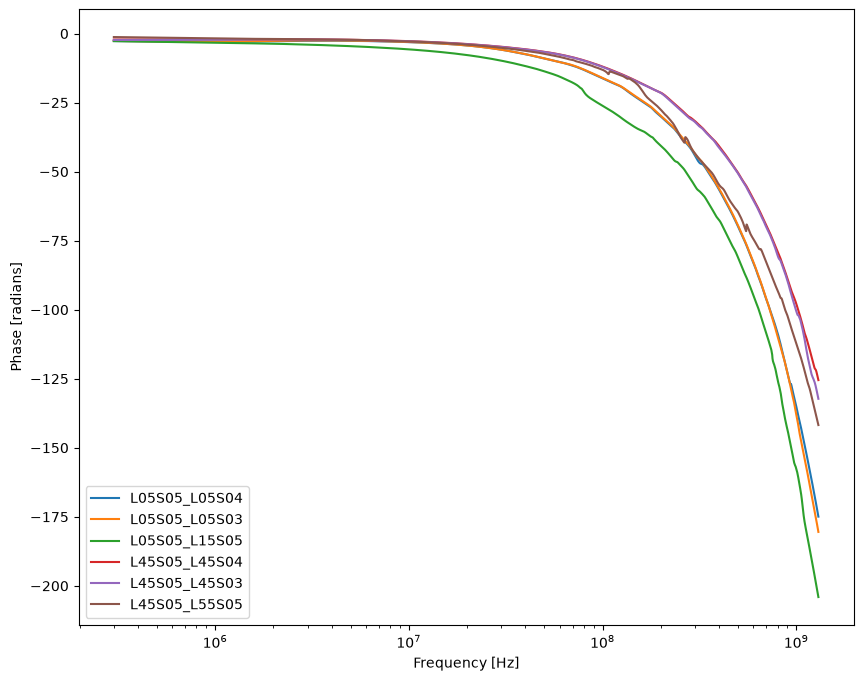

In [4]:
for key in keys_xtalk:
    dft = dfs[key]
    plt.plot(dft['freq'], dft['s21_m'], label = f'{key[:6]} xtalk to {key[7:13]}')

plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude [dB]')


    
plt.legend()
plt.xscale('log')
#plt.ylim(-10, 1)

plt.savefig('s21_xtalk_magnitude_all.pdf')

plt.show()

for key in keys_xtalk:
    dft = dfs[key]
    plt.plot(dft['freq'], dft['s21_p'], label = key)
plt.xlabel('Frequency [Hz]')
plt.ylabel('Phase [radians]')

plt.legend()
plt.xscale('log')

plt.savefig('s21_xtalk_phase_all.pdf')


Text(0.5, 0.98, 'S11')

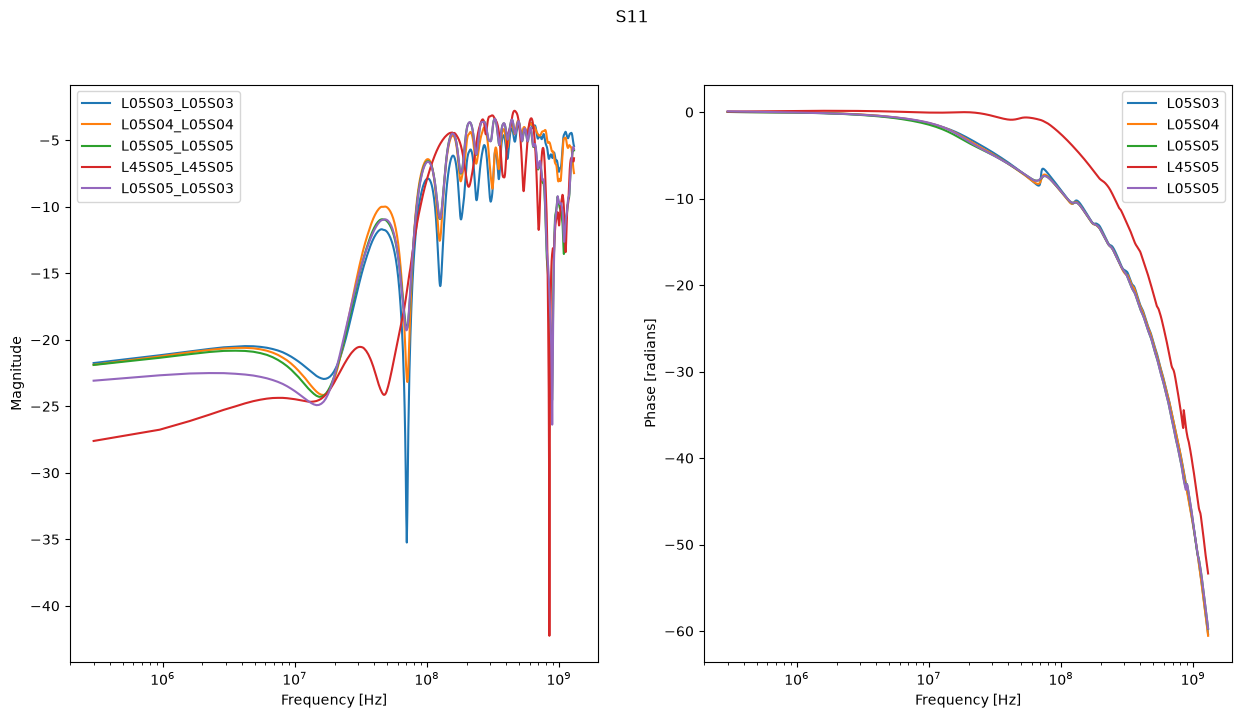

In [5]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 7.5))

for key in [*keys_thru, 'L05S05_L05S03']:
    dft = dfs[key]
    ax1.plot(dft['freq'], dft['s11_m'], label = key)

    # ax1.plot(dft['freq'], lowpass_mag(dft['freq'], 8, 0), label = key)

ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Magnitude')


    
ax1.legend()
ax1.set_xscale('log')
# ax1.set_ylim(-15, 1)

for key in [*keys_thru, 'L05S05_L05S03']:
    dft = dfs[key]
    ax2.plot(dft['freq'], dft['s11_p'], label = f'{key[:6]}')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [radians]')

ax2.legend()
ax2.set_xscale('log')

plt.suptitle('S11')

Text(0.5, 1.0, 'Phase Spectrum')

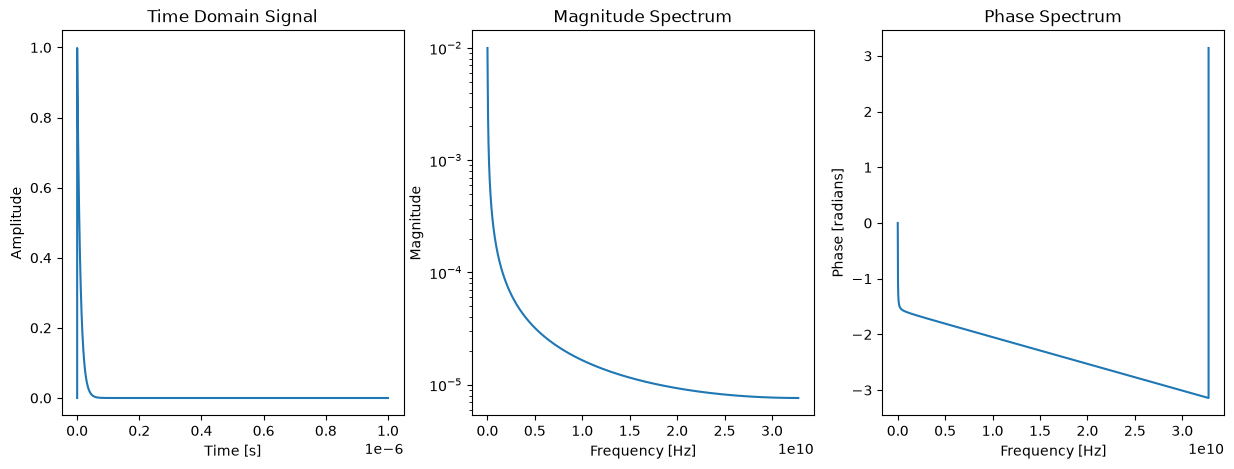

In [6]:
N, tau = 2**16, 1E-6 # number of samples and signal duration in seconds
T = tau / N  # sampling interval
t = np.arange(N) * T  # sample times

x = [0 if t == 0 else np.exp(-t/10E-9) for t in t]
#x = [1 if t == 0 else 0 for t in t]
#x = np.sin(2 * np.pi * 50E6 * t)  # 50 Hz sine wave

f = rfftfreq(N, T)  # frequency values

X = rfft(x) / N

X_mag = abs(X)  # Magnitude spectrum
X_phase = np.angle(X)



fig, [ax0, ax1, ax2] = plt.subplots(1,3, figsize=(15,5))

ax0.plot(t, x)
ax0.set_xlabel('Time [s]')
ax0.set_ylabel('Amplitude')
ax0.set_title('Time Domain Signal')


ax1.plot(f, X_mag)
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Magnitude')
ax1.set_title('Magnitude Spectrum')
ax1.set_yscale('log')

ax2.plot(f, X_phase)
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [radians]')
ax2.set_title('Phase Spectrum')



In [ ]:
def transfer_function(dft, f, mag_col, phase_col):
    """Complex transfer function H(f) on the FFT grid f, from VNA dB/radian columns."""
    freq = dft['freq'].to_numpy()
    mag_lin = 10**(dft[mag_col].to_numpy() / 20)              # dB -> linear amplitude
    phase = dft[phase_col].to_numpy()                         # already radians and unwrapped (data-loading cell)

    # hold the first point below the VNA band; roll off to zero above it
    mag_i = np.interp(f, freq, mag_lin, left=mag_lin[0], right=0)
    phase_i = np.interp(f, freq, phase, left=phase[0], right=phase[-1])
    return mag_i * np.exp(1j * phase_i)


x_f = {}

for key in dfs:
    x_f[key] = irfft(X * transfer_function(dfs[key], f, 's21_m', 's21_p')) * N


In [16]:
x_f11 = {}

for key in dfs:
    x_f11[key] = irfft(X * transfer_function(dfs[key], f, 's11_m', 's11_p')) * N


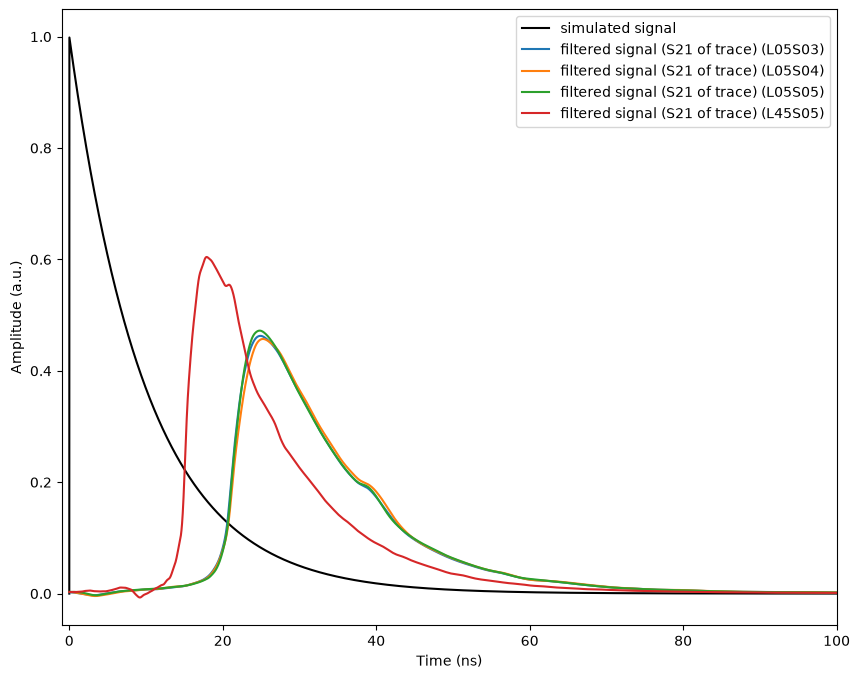

In [17]:
#plt.figure(figsize=(10, 7.5))


plt.plot(t/1E-9, x, label='simulated signal', color='black')

for i, key in enumerate(keys_thru):
    plt.plot(t/1E-9, x_f[key], label=f'filtered signal (S21 of trace) ({key[:6]})', color=f'C{i}')
    # scaled version for visibility

plt.xlim(-1, 100)

plt.xlabel('Time (ns)')
plt.ylabel('Amplitude (a.u.)')

plt.legend(ncol=1)
# plt.yscale('log')
#plt.ylim(-1E-2, 1E-2)

plt.savefig('S21_thru_waveforms.pdf')



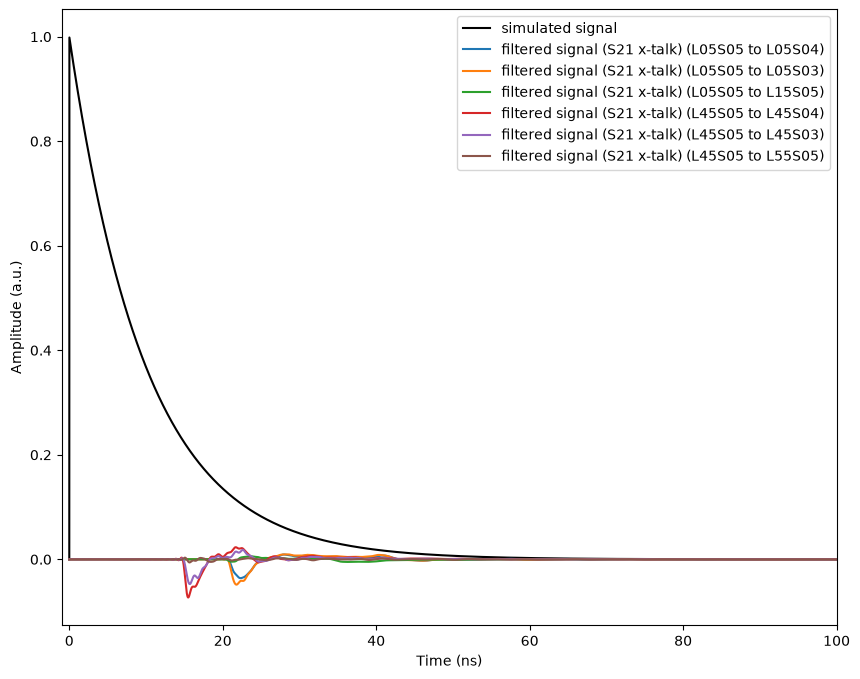

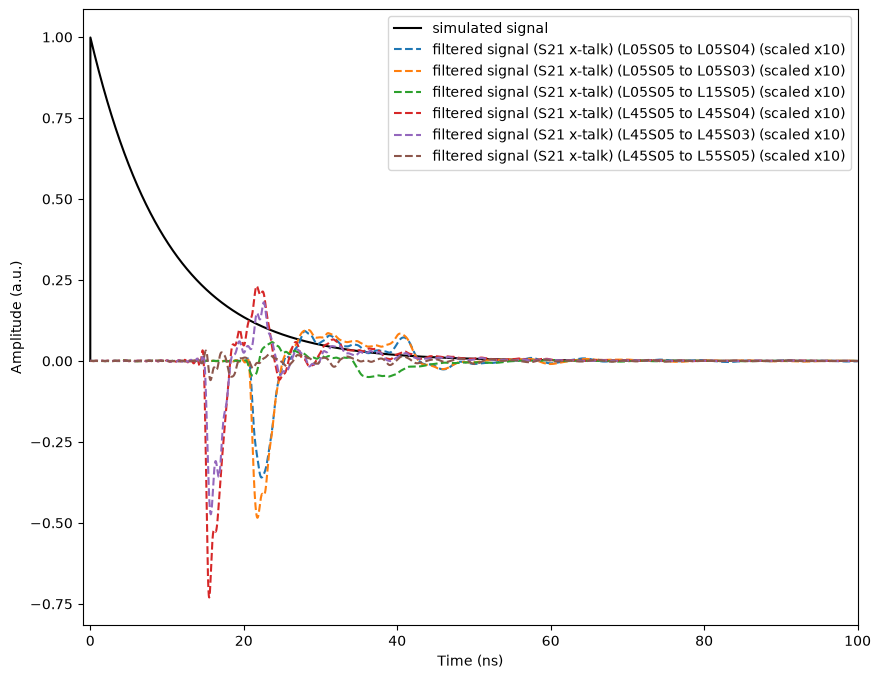

In [14]:
#plt.figure(figsize=(15, 7.5))


plt.plot(t/1E-9, x, label='simulated signal', color='black')

for i, key in enumerate(keys_xtalk):
    plt.plot(t/1E-9, x_f[key], label=f'filtered signal (S21 x-talk) ({key[:6]} to {key[7:13]})', color=f'C{i}')
    # scaled version for visibility
    # if key in keys_xtalk:
    #     plt.plot(t/1E-9, x_f[key]*200   ,  '--', label=f'filtered signal (S21 x-talk) ({key[:6]} to {key[7:13]}) (scaled x200)', color=f'C{i}')

plt.xlim(-1, 100)

plt.xlabel('Time (ns)')
plt.ylabel('Amplitude (a.u.)')

plt.legend(ncol=1)
# plt.yscale('log')
#plt.ylim(-1E-2, 1E-2)

plt.savefig('S21_xtalk_waveforms.pdf')
plt.show()

plt.plot(t/1E-9, x, label='simulated signal', color='black')

for i, key in enumerate(keys_xtalk):
    #plt.plot(t/1E-9, x_f[key], label=f'filtered signal (S21 x-talk) ({key[:6]} to {key[7:13]})', color=f'C{i}')
    # scaled version for visibility
    # if key in keys_xtalk:
    plt.plot(t/1E-9, x_f[key]*10   ,  '--', label=f'filtered signal (S21 x-talk) ({key[:6]} to {key[7:13]}) (scaled x10)', color=f'C{i}')

plt.xlim(-1, 100)

plt.xlabel('Time (ns)')
plt.ylabel('Amplitude (a.u.)')

plt.legend(ncol=1)
# plt.yscale('log')
#plt.ylim(-1E-2, 1E-2)

plt.savefig('S21_xtalk_waveforms_scaled.pdf')

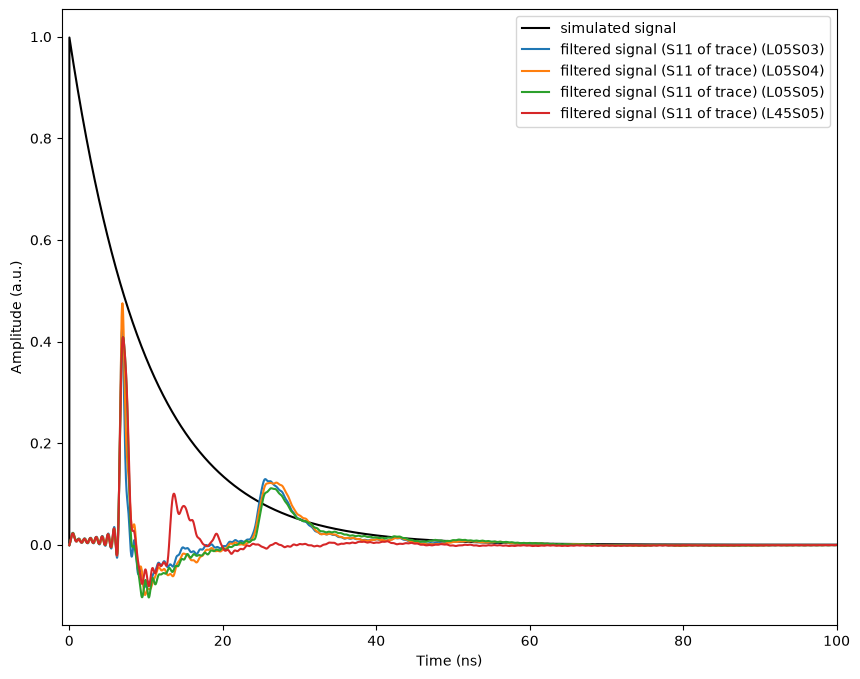

In [11]:
#plt.figure(figsize=(15, 7.5))


plt.plot(t/1E-9, x, label='simulated signal', color='black')

for i, key in enumerate(keys_thru):
    plt.plot(t/1E-9, x_f11[key], label=f'filtered signal (S11 of trace) ({key[:6]})', color=f'C{i}')
    # scaled version for visibility
    # if key in keys_xtalk:
    #     plt.plot(t/1E-9, x_f11[key]*200   ,  '--', label=f'trace response filtered signal ({key}, scaled x200)', color=f'C{i}')

plt.xlim(-1, 100)

plt.xlabel('Time (ns)')
plt.ylabel('Amplitude (a.u.)')

plt.legend(ncol=1)
# plt.yscale('log')
#plt.ylim(-1E-2, 1E-2)
plt.savefig('S11_tdr_waveforms.pdf')


